<a href="https://colab.research.google.com/github/kelvin-yg98/Kelvin-Programming/blob/main/Benchmarking_Linear_Regression_and_SVR_for_Daily_Climate_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# 1. Install kagglehub and load dependencies
!pip install -q kagglehub

import os
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.svm import SVR
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error



In [2]:
# 2. Download Daily Climate dataset from Kaggle
path = kagglehub.dataset_download("sumanthvrao/daily-climate-time-series-data")
print("Dataset downloaded to path:", path)

# Locate the training CSV file (e.g., Daily Climate Time Series - Train)
csv_file = [f for f in os.listdir(path) if 'train' in f.lower() and f.endswith('.csv')][0]
df = pd.read_csv(os.path.join(path, csv_file))



Using Colab cache for faster access to the 'daily-climate-time-series-data' dataset.
Dataset downloaded to path: /kaggle/input/daily-climate-time-series-data


In [3]:
# 3. Data Preprocessing & Feature Engineering for Time Series
# Convert date column and set as index
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date')

# Let's forecast 'meantemp' (Mean Temperature) using a Lag Feature (yesterday's temp to predict today's temp)
df['Lag_1_Temp'] = df['meantemp'].shift(1)
df = df.dropna().reset_index(drop=True)

# Define Features (X) and Target (y)
X = df[['Lag_1_Temp']]
y = df['meantemp']

# Chronological Train-Test Split (80% train, 20% test — never shuffle time series!)
train_size = int(len(df) * 0.8)
X_train, X_test = X.iloc[:train_size], X.iloc[train_size:]
y_train, y_test = y.iloc[:train_size], y.iloc[train_size:]
test_dates = df['date'].iloc[train_size:]



In [4]:
# 4. Feature Scaling (Crucial for SVR distance calculations)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)



In [5]:
# 5. Model 1: Linear Regression
lin_reg = LinearRegression()
lin_reg.fit(X_train_scaled, y_train)
y_pred_lr = lin_reg.predict(X_test_scaled)



In [6]:
# 6. Model 2: Support Vector Regression (SVR with RBF kernel to capture non-linear trends)
svr_model = SVR(kernel='rbf', C=100, gamma=0.1, epsilon=0.1)
svr_model.fit(X_train_scaled, y_train)
y_pred_svr = svr_model.predict(X_test_scaled)



In [7]:
# 7. Print Performance Metrics (RMSE & MAE)
print("--- Model Evaluation (Test Set) ---")
print(f"Linear Regression RMSE: np.sqrt({mean_squared_error(y_test, y_pred_lr):.3f}) = {np.sqrt(mean_squared_error(y_test, y_pred_lr)):.3f}")
print(f"SVR RMSE:             np.sqrt({mean_squared_error(y_test, y_pred_svr):.3f}) = {np.sqrt(mean_squared_error(y_test, y_pred_svr)):.3f}")



--- Model Evaluation (Test Set) ---
Linear Regression RMSE: np.sqrt(2.817) = 1.678
SVR RMSE:             np.sqrt(2.714) = 1.647


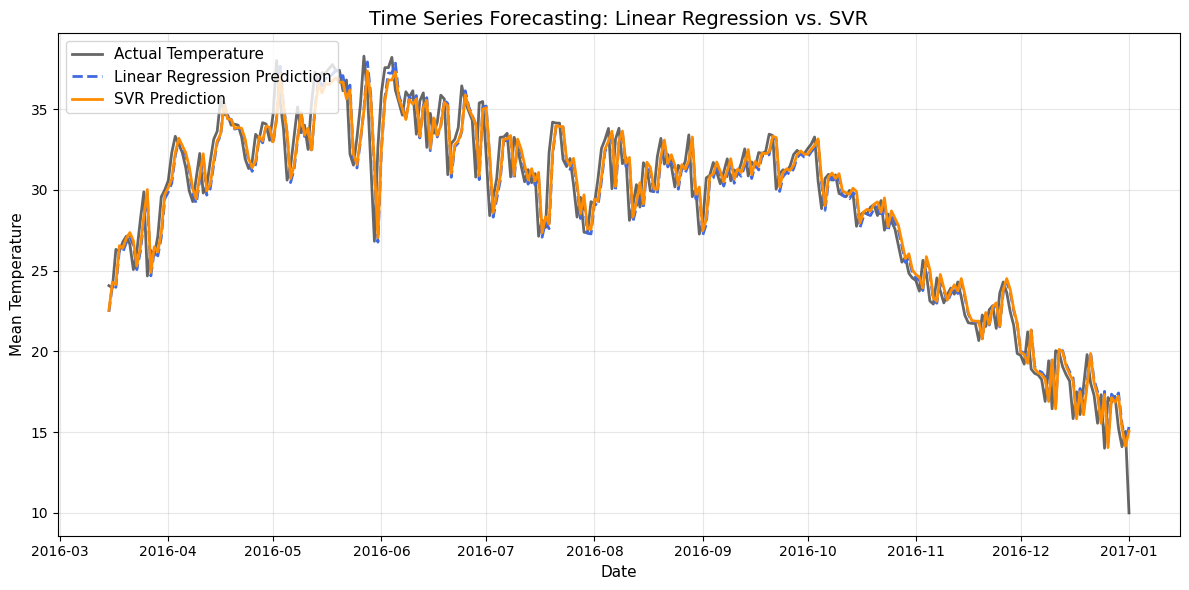

In [8]:
# 8. Plotting the Comparative Forecast Graph
plt.figure(figsize=(12, 6))
plt.plot(test_dates, y_test, label='Actual Temperature', color='black', alpha=0.6, linewidth=2)
plt.plot(test_dates, y_pred_lr, label='Linear Regression Prediction', color='royalblue', linestyle='--', linewidth=2)
plt.plot(test_dates, y_pred_svr, label='SVR Prediction', color='darkorange', linewidth=2)

plt.title('Time Series Forecasting: Linear Regression vs. SVR', fontsize=14)
plt.xlabel('Date', fontsize=11)
plt.ylabel('Mean Temperature', fontsize=11)
plt.legend(loc='upper left', fontsize=11)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
"""
=============================================================================
PROJECT CONCLUSION: TIME SERIES CLIMATE FORECASTING (Linear Reg vs. SVR)
=============================================================================
1. Data Ingestion & Setup: Downloaded daily climate data from Kaggle using
   kagglehub and arranged it chronologically (preserving time series order).
2. Feature Engineering: Created a lag feature (using yesterday's temperature
   to forecast today's) to capture weather autocorrelation.
3. Model Training: Compared a parametric Linear Regression baseline against
   a Support Vector Regression (SVR) model designed to handle noise via margins.
4. Findings: Both models yielded very similar forecast trajectories because
   daily temperature transitions are largely steady and linear. SVR successfully
   filtered out minor day-to-day fluctuations using its epsilon-tube optimization.
=============================================================================
"""